In [ ]:
#Import libraries and upload dataset
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

Saving spam_sms.csv to spam_sms (1).csv


In [ ]:
#Read the CSV
data = pd.read_csv("spam_sms.csv", encoding="latin-1")

print("Original shape:", data.shape)
print(data.head())
print(data.columns)

Original shape: (5572, 2)
     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Index(['v1', 'v2'], dtype='object')


In [ ]:
'''The standard Kaggle file may contain extra columns such as Unnamed: 2, Unnamed: 3, and Unnamed: 4.
We only need the label and message '''
#Keep relevant columns and rename them
data = data[['v1', 'v2']].copy()

data.columns = ['label', 'message']

print(data.head())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [ ]:
#Handle missing values and duplicates
print("Missing values before cleaning:")
print(data.isnull().sum())

data = data.dropna(subset=['label', 'message'])

data['message'] = data['message'].astype(str)

data = data.drop_duplicates()

data = data.reset_index(drop=True)

print("Shape after cleaning:", data.shape)
print(data['label'].value_counts())

Missing values before cleaning:
label      0
message    0
dtype: int64
Shape after cleaning: (5169, 2)
label
ham     4516
spam     653
Name: count, dtype: int64


In [ ]:
#sample the data safely
from sklearn.model_selection import train_test_split

data = pd.read_csv("spam_sms.csv", encoding="latin-1")
data = data[['v1', 'v2']].copy()
data.columns = ['label', 'message']

data = data.dropna(subset=['label', 'message'])
data = data.drop_duplicates().reset_index(drop=True)

data, _ = train_test_split(
    data,
    train_size=2000,
    random_state=42,
    stratify=data['label']
)

data = data.reset_index(drop=True)

print(data.shape)
print(data['label'].value_counts())

(2000, 2)
label
ham     1747
spam     253
Name: count, dtype: int64


In [ ]:
#Clean messages and encode labels
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

data['message'] = data['message'].apply(clean_text)

data['label'] = data['label'].map({
    'ham': 0,
    'spam': 1
})

print(data.head())

   label                                            message
0      1  500 new mobiles from 2004, must go! txt: nokia...
1      0                             are you this much buzy
2      0             itâãã·s ã¥â£6 to get in, is that ok?
3      0  aiyah sorry lor... i watch tv watch until i fo...
4      0  kinda. first one gets in at twelve! aah. speak...


In [ ]:
X = data['message']
y = data['label']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1600
Testing samples: 400


In [ ]:
#Tokenization converts words into integer IDs that the neural network can process.
from tensorflow.keras.preprocessing.text import Tokenizer

vocab_size = 5000 #use up to the 5,000 most frequent word IDs,including the reserved out-of-vocabulary token.

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>" #represents words that were not included in the vocabulary.
)

tokenizer.fit_on_texts(X_train) #learns word frequencies and IDs using training messages only.

print("Total unique words:", len(tokenizer.word_index))
print(list(tokenizer.word_index.items())[:15])

Total unique words: 4364
[('<OOV>', 1), ('i', 2), ('to', 3), ('you', 4), ('the', 5), ('a', 6), ('u', 7), ('and', 8), ('in', 9), ('is', 10), ('me', 11), ('for', 12), ('my', 13), ('your', 14), ('it', 15)]


In [ ]:
#Convert messages into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Original message:", X_train.iloc[0])
print("Integer sequence:", X_train_seq[0])

Original message: hi dude hw r u da realy mising u today
Integer sequence: [80, 438, 1844, 102, 7, 96, 1214, 1845, 7, 91]


In [ ]:
'''Padding makes every message the same length.
For SMS messages, we'll start with max_length = 50.'''
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_length = 50

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding='pre',
    truncating='pre'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding='pre',
    truncating='pre'
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (1600, 50)
Testing shape: (400, 50)


In [ ]:
#Build the model(Simple Rnn)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=32,
        mask_zero=True
    ),

    SimpleRNN(32),

    Dropout(0.3),

    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Compile the model
model.compile(
    optimizer='adam', #adjusts model weights during training.
    loss='binary_crossentropy', #measures prediction error for the two classes.
    metrics=['accuracy'] #measures the proportion of correct predictions.
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

In [ ]:
#Train the model
history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.8453 - loss: 0.4588 - val_accuracy: 0.9156 - val_loss: 0.2789
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9586 - loss: 0.1677 - val_accuracy: 0.9438 - val_loss: 0.1859
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9695 - loss: 0.1201 - val_accuracy: 0.9375 - val_loss: 0.2126
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9867 - loss: 0.0685 - val_accuracy: 0.9531 - val_loss: 0.1732
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9930 - loss: 0.0455 - val_accuracy: 0.9469 - val_loss: 0.1627
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.9961 - loss: 0.0294 - val_accuracy: 0.9469 - val_loss: 0.1815
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9992 - loss: 0.0171 - val_accuracy: 0.9406 - val_loss: 0.1797


In [ ]:
#Evaluate with accuracy, precision, recall and F1-score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_prob = model.predict(X_test_pad).ravel()

y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, zero_division=0))

print("\nDetailed classification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Ham', 'Spam'],
        zero_division=0
    )
)

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step
Accuracy : 0.965
Precision: 0.9743589743589743
Recall   : 0.7450980392156863
F1-score : 0.8444444444444444

Detailed classification report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       349
        Spam       0.97      0.75      0.84        51

    accuracy                           0.96       400
   macro avg       0.97      0.87      0.91       400
weighted avg       0.97      0.96      0.96       400



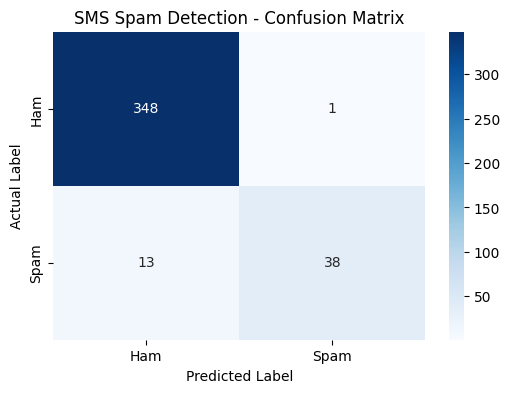

In [ ]:
#Display the confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('SMS Spam Detection - Confusion Matrix')

plt.show()

In [ ]:
#Predict unseen SMS messages
def predict_sms(message):
    cleaned_message = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned_message])

    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding='pre',
        truncating='pre'
    )

    probability = float(model.predict(padded, verbose=0)[0][0])

    prediction = 'SPAM' if probability >= 0.5 else 'HAM'

    print("Message:", message)
    print("Predicted class:", prediction)
    print("Spam probability:", round(probability, 4))


predict_sms("Congratulations! You have won a free prize. Claim it now!")
print()
predict_sms("Hi, are we meeting at the library after class?")

Message: Congratulations! You have won a free prize. Claim it now!
Predicted class: HAM
Spam probability: 0.1347

Message: Hi, are we meeting at the library after class?
Predicted class: HAM
Spam probability: 0.0082


In [ ]:
#Plot accuracy and loss

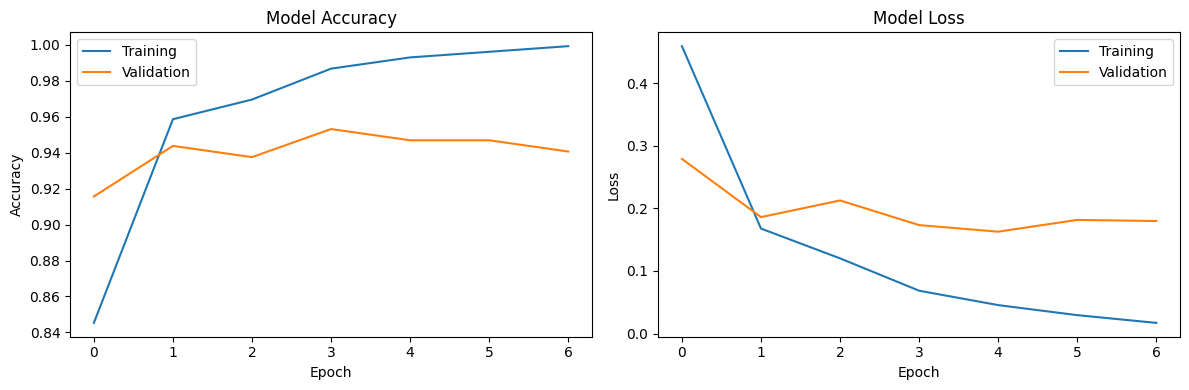

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
### Early Stopping Configured
#The model training above has been configured with the `EarlyStopping` callback to prevent overfitting.

In [ ]:

def predict_sms(message):
    # Apply the same preprocessing used during training
    cleaned_message = clean_text(message)

    # Convert text into a sequence of numbers
    sequence = tokenizer.texts_to_sequences([cleaned_message])

    # Pad the sequence exactly as during training
    padded_sequence = pad_sequences(
        sequence,
        maxlen=max_length,
        padding='pre',
        truncating='pre'
    )

    # Predict the probability of spam
    probability = model.predict(padded_sequence, verbose=0)[0][0]

    # Classify the message
    if probability >= 0.5:
        print("Prediction: SPAM")
    else:
        print("Prediction: GENUINE (HAM)")

    print(f"Spam probability: {probability * 100:.2f}%")


# Enter your own SMS below
sms = input("Enter an SMS message: ")
predict_sms(sms)


Enter an SMS message:  u are being ripped off! Get your mobile content from www.clubmoby.com call 08717509990 poly/true/Pix/Ringtones/Games six downloads for only 3
Prediction: SPAM
Spam probability: 96.58%
